# Fixing the run's record, number by number: a demo of `eval.py`

**Artifact:** `art_LzP2qPwUrANz` (evaluation, iteration 7, Step 0). It runs on CPU only, no model is run, and the demo finishes in seconds.

The research run asks whether prompt bans and other context changes make an open-weight LLM write a *different* algorithm (BFS instead of DFS, Dijkstra, ...), and where inside the model that choice is held. Before the paper quotes the run report, this artifact re-derives every number the report took from four iteration-6 experiments, working from their raw rows:
- `art_lpQalcAXMGr1`, the engine control;
- `art_rMlbrjVB1c__`, the exchange and site experiment;
- `art_zNyBP6zieI5u`, Gemma;
- `art_dbUtqBjT0tPf`, the NLA experiment.

It then corrects the report in place with **54 verbatim `old_text -> new_text` pairs** marked `(iteration-7 correction)`. Each pair carries the values behind it as `{recorded, recomputed, status, source}`.

`eval.py` is the orchestrator. It runs these stages in order:
1. **Items 0a to 0l** recompute values from the raw rows and hand their edits to an `Editor`. The item code lives in `src/items_qwen.py`, `src/items_other.py` and `src/figmarkers.py`. A `Registry` numbers the edits `C7-01` to `C7-54`.
2. The **judges (0i)** and the **positioning pass (0k)** feed `eval.py`'s own row templates, `table278_row` and `positioning_row`.
3. The **apply test** checks four things for every correction:
   - its old text occurs exactly once in the report;
   - its new text is present after applying;
   - the marker appears exactly once;
   - it overlaps no other correction.
4. The **residual-claim lint** applies regex rules for wrong claims left in the prose. The **value ledger** gives every value one of four statuses: MATCH, NEW, CARRIED or CORRECTED.
5. The script writes the tables, runs an independent standard-library audit with placebos, and writes `eval_out.json`.

**What this notebook runs.** The item stages need the 69 vendored raw input files in the repository's `inputs/` folder, so their code is shown but not executed. `mini_demo_data.json` holds the 54 corrections they produced, which is the `corrections` dataset of `full_eval_out.json`. It also holds the few small inputs that the rest of `eval.py` reads:
- the report's section headings;
- the cached judge and positioning results;
- two cached arXiv pages.

With these, the rest of the script runs with its original code:
- the stored corrections go back through the same `Editor` calls, in their original order, on a line-faithful excerpt of the report;
- `table278_row` and `positioning_row` rebuild two of the corrections from the cached results, and the venue check re-derives the **3 CORRECTED** values;
- the apply test, the diff, the lint, the value statuses and the tables then run unchanged.

**Expected at the full setting (`N_REPLAY = 52`):**
- the apply test passes **54/54** with no overlaps;
- the lint goes from **16 flags to 0**, and the 16 are the same flags the full run found;
- every stored status is re-derived.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
"""Iteration-7 Step 0: repair the run's record number by number (items 0a to 0l), prove that every correction
applies, lint the corrected report for leftover wrong claims, and write eval_out.json (exp_eval_sol_out).

Usage: uv run eval.py --stages all          (everything, including the paid judges and the web positioning pass)
       uv run eval.py --stages offline      (reuse the cached judge and web results; no network)
"""

from __future__ import annotations

import argparse
import csv
import json
import resource
import subprocess
import sys
import time
from pathlib import Path

# eval.py: WS = Path(__file__).resolve().parent; sys.path.insert(0, str(WS / "src"))  -> WS is set in the
# src/common.py cell below, and the src/ modules eval.py imports are copied into the notebook instead
from loguru import logger  # noqa: E402

# imports of the src/ modules copied below (common.py, corrections.py, editor.py, items_qwen.py)
import difflib
import hashlib
import re
from dataclasses import asdict, dataclass, field
from typing import Any

# notebook only: the data loader (next cell) and the plots
import matplotlib.pyplot as plt
import numpy as np

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/evaluation-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]  # the 54 corrections, in id order (C7-01 ... C7-54)
print(f"{data['metadata']['evaluation_name']} (report read {data['metadata']['read_date']}): dataset "
      f"'{data['datasets'][0]['dataset']}', {len(examples)} corrections; example keys: {sorted(examples[0])}")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
iteration-7 Step 0 record repair (report read 2026-10-22): dataset 'corrections', 54 corrections; example keys: ['eval_applies', 'eval_n_values', 'input', 'metadata_also_items', 'metadata_id', 'metadata_item', 'metadata_kind', 'metadata_line_at_read', 'metadata_rationale', 'metadata_registered_by', 'metadata_section', 'metadata_table', 'metadata_values', 'output']


## Config

`eval.py` has a single command-line option, `--stages`:
- `all` re-runs the paid blind judges and the live web pass;
- `offline` reuses their cached results.

Only `offline` can run here, because the cached results ship inside `mini_demo_data.json`.

The one size knob is `N_REPLAY`, the number of item-stage corrections fed back through the `Editor`. They are fed in their original order: first `C7-01` to `C7-20`, then the paragraph edits `C7-23` to `C7-54`. The two rows that `eval.py` builds with its own templates are always rebuilt: `C7-21` (Table 278) and `C7-22` (Table 277, row 66). The full run has all 52, which with the two template rows makes 54 corrections. The whole notebook takes a few seconds even then.

In [5]:
# ---- Config ----
N_REPLAY = 52          # item-stage corrections replayed through the Editor (minimum 1)
# N_REPLAY = 52        # original: every correction of the full run (52 + the 2 template rows = 54)
SHOW_DIFF_LINES = 20   # lines of report.diff printed after the apply test (each cut to 160 characters)

## Shared helpers (`src/common.py`)

`eval.py` imports its paths, constants, and its JSON and hash helpers from `src/common.py`. The definitions it uses are copied below unchanged, with two exceptions:
- `WS` points to a fresh output folder, `demo_outputs/`, because a notebook has no `__file__`;
- the lookup of the other artifacts' folders (`DEPS_ROOT`, `dep_dir`) is left out, because the demo reads nothing from them.

In [6]:
"""Shared paths, IO, hashing and logging for the iteration-7 record repair (Step 0).

Every path is derived from this file's location (the workspace root) or from the AII_RUN_ROOT environment
variable, so no absolute server path is written into any published file. Inputs are read from the vendored
copies under inputs/<artifact_id>/ once src/stage_inputs.py has resolved and hashed them.
"""

# common.py: WS = Path(__file__).resolve().parents[1] -- a notebook has no __file__, so everything this demo
# writes goes to one folder, with the same relative layout eval.py writes next to itself
WS = Path.cwd() / "demo_outputs"
WS.mkdir(exist_ok=True)
# (DEPS_ROOT, DEP_REL, dep_dir() and the other folder lookups are left out: nothing is read from other artifacts.
#  src_ref, read_jsonl, write_jsonl, sha256_text, truthy, fmt and fmt_p are used only by the item modules.)

INPUTS = WS / "inputs"
TABLES = WS / "tables"
AUDIT = WS / "audit"
LOGS = WS / "logs"
RESULTS = WS / "results"
READ_DATE = "2026-10-22"
MARK = "(iteration-7 correction)"


def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def inp(artifact: str, rel: str) -> Path:
    """Path of a vendored input file."""
    return INPUTS / artifact / rel


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=indent, default=_default, ensure_ascii=False) + "\n")


def _default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

## The correction registry, value statuses, apply test and lint (`src/corrections.py`)

This module is copied unchanged.
- **`status_of` and `V`** give each value its status by comparing the number the report recorded with the recomputed one. A value is `NEW` when the report recorded nothing, and `CARRIED` when it cannot be recomputed. Otherwise it is `MATCH` or `CORRECTED`, judged within its tolerance class:

  | Class | Tolerance |
  |-|-|
  | counts | exact |
  | proportions | ±0.005 |
  | effects and ratios | ±0.01 |
  | intervals | ±0.01 per bound |
  | p values | within 1% (relative) |
  | text | exact match |
- **`Registry.add`** numbers the corrections `C7-xx`, appends the marker when it is missing, and records the line where the old text was read.
- **`apply_all`** is the apply test (metric M1). It applies the corrections in file order and checks the contract of each one.
- **`lint`** holds the residual-claim rules (metric M2). It scans the iteration-6 prose from line 5497 up to the references.

In [7]:
"""A3/A4: the correction registry, value statuses, the apply test and the residual-claim lint (M1, M2).

A correction is {id 'C7-xx', item, section, table, line_at_read, kind, old_text, new_text, values, rationale}.
kind is replace | insert_after | table_replace. For insert_after, old_text is the unique anchor and the new text
is inserted after it (the stored new_text is the inserted block only). Every new_text carries the marker
'(iteration-7 correction)' exactly once. Numbers in new_text come from recomputed values by template.
"""
# from common import MARK   (defined in the src/common.py cell above)

TOL = {"count": 0.0, "prop": 0.005, "effect": 0.01, "ci": 0.01, "p": None, "text": None, "ratio": 0.01}


def status_of(recorded: Any, recomputed: Any, tol: str) -> str:
    if recorded is None:
        return "NEW"
    if recomputed is None:
        return "CARRIED"
    if tol == "text":
        return "MATCH" if str(recorded) == str(recomputed) else "CORRECTED"
    if isinstance(recorded, (list, tuple)):
        ok = all(abs(float(a) - float(b)) <= TOL["ci"] + 1e-12 for a, b in zip(recorded, recomputed))
        return "MATCH" if ok and len(recorded) == len(recomputed) else "CORRECTED"
    r, c = float(recorded), float(recomputed)
    if tol == "p":
        if r < 1e-6 and c < 1e-6:
            return "MATCH"
        return "MATCH" if abs(r - c) <= 0.01 * max(abs(r), 1e-300) else "CORRECTED"
    return "MATCH" if abs(r - c) <= TOL[tol] + 1e-12 else "CORRECTED"


def V(name: str, recomputed: Any, recorded: Any = None, *, tol: str = "count", source: str = "",
      carried: bool = False, printed: Any = None) -> dict:
    st = "CARRIED" if carried else status_of(recorded, recomputed, tol)
    out = {"name": name, "recorded": recorded, "recomputed": recomputed, "status": st, "tolerance": tol,
           "source": source}
    if printed is not None:
        out["printed_in_report"] = printed
    return out


@dataclass
class Correction:
    id: str
    item: str
    section: str
    table: str | None
    line_at_read: int | None
    kind: str
    old_text: str
    new_text: str
    values: list[dict] = field(default_factory=list)
    rationale: str = ""
    also_items: list[str] = field(default_factory=list)


class Registry:
    def __init__(self, report: str):
        self.report = report
        self.items: list[Correction] = []
        self.discrepancies: list[dict] = []

    def line_of(self, text: str) -> int | None:
        i = self.report.find(text)
        return None if i < 0 else self.report.count("\n", 0, i) + 1

    def add(self, *, item: str, section: str, kind: str, old_text: str, new_text: str, values: list[dict],
            rationale: str, table: str | None = None, also_items: list[str] | None = None) -> Correction:
        assert kind in ("replace", "insert_after", "table_replace"), kind
        if MARK not in new_text:
            new_text = new_text.rstrip() + " " + MARK
        cid = f"C7-{len(self.items) + 1:02d}"
        c = Correction(id=cid, item=item, section=section, table=table, line_at_read=self.line_of(old_text),
                       kind=kind, old_text=old_text, new_text=new_text, values=values, rationale=rationale,
                       also_items=also_items or [])
        self.items.append(c)
        for v in values:
            if v["status"] == "CORRECTED":
                self.discrepancies.append({"correction": cid, **v})
        return c

    def as_dicts(self) -> list[dict]:
        return [asdict(c) for c in self.items]


def apply_all(report: str, corrections: list[dict]) -> tuple[str, dict]:
    """Apply in file order (by position of old_text in the uncorrected report) and check the contract."""
    checks = []
    for c in corrections:
        n = report.count(c["old_text"])
        checks.append({"id": c["id"], "old_found_exactly_once": n == 1, "n_found": n,
                       "marker_once": c["new_text"].count(MARK) == 1})
    # overlap check on spans in the uncorrected report
    spans = []
    for c in corrections:
        i = report.find(c["old_text"])
        if i >= 0:
            spans.append((i, i + len(c["old_text"]), c["id"]))
    spans.sort()
    overlaps = [(a[2], b[2]) for a, b in zip(spans, spans[1:]) if b[0] < a[1]]
    order = sorted(corrections, key=lambda c: report.find(c["old_text"]))
    out = report
    for c in order:
        if out.count(c["old_text"]) != 1:
            continue
        if c["kind"] == "insert_after":
            out = out.replace(c["old_text"], c["old_text"] + c["new_text"], 1)
        else:
            out = out.replace(c["old_text"], c["new_text"], 1)
    for ch in checks:
        c = next(x for x in corrections if x["id"] == ch["id"])
        ch["new_present_after"] = c["new_text"] in out
        ch["pass"] = ch["old_found_exactly_once"] and ch["new_present_after"] and ch["marker_once"]
    n_pass = sum(ch["pass"] for ch in checks)
    res = {"n": len(checks), "n_pass": n_pass, "pass_rate": n_pass / len(checks) if checks else None,
           "overlaps": overlaps, "checks": checks, "passed": n_pass == len(checks) and not overlaps}
    return out, res


def unified_diff(a: str, b: str) -> str:
    return "".join(difflib.unified_diff(a.splitlines(keepends=True), b.splitlines(keepends=True),
                                        fromfile="current_report.md", tofile="report_corrected.md", n=1))


# ---------------------------------------------------------------- M2: residual-claim lint
STAGEA_CTX = re.compile(r"exchang|Stage A|task-specification states|transfer", re.I)
STAGEA_NUM = re.compile(r"(?<![\d.])0\.(?:80|57|47|33|567|467|333)(?!\d)")
LINT = {
    "post_hoc_form_survives": re.compile(r"post-hoc form survives", re.I),
    "measured_in_three_models": re.compile(r"measured in three models", re.I),
    "in_all_three_read_position": re.compile(r"In all three (models )?the read position", re.I),
    "essentially_one_direction": re.compile(r"essentially one direction", re.I),
    "every_edit_pass_or_breaks": re.compile(r"every (fork )?edit[^.]{0,80}?(pass rate|breaks)", re.I),
    "post_hoc_ordering_noise_sites": re.compile(r"post-hoc ordering of noise sites", re.I),
}
TOP5 = re.compile(r"(top-five (direction|push)|activation version of the prohibition)[^.]*breaks programs before",
                  re.I)


def _sentences(par: str) -> list[str]:
    return re.split(r"(?<=[.;])\s+(?=[A-Z*(])", par)


def lint(text: str, start_line: int = 5497) -> list[dict]:
    """Flag leftover wrong claims in iteration-6 prose (Sections 6.4 to the closing). Table rows are skipped
    for the Stage A share check (their captions and columns carry the definitions)."""
    hits = []
    lines = text.splitlines()
    end = next((i for i, l in enumerate(lines) if l.startswith("# References")), len(lines))
    for ln in range(start_line - 1, end):
        line = lines[ln]
        if MARK in line and "*(Correction, iteration 6" not in line:
            pass
        for name, rx in LINT.items():
            for m in rx.finditer(line):
                hits.append({"line": ln + 1, "rule": name, "snippet": line[max(0, m.start() - 60):m.end() + 60]})
        for m in TOP5.finditer(line):
            a = line.rfind(". ", 0, m.start())
            b = line.find(".", m.end())
            seg = line[a + 1 if a >= 0 else 0: b + 1 if b > 0 else len(line)]
            if "ban unit" not in seg:
                hits.append({"line": ln + 1, "rule": "top5_without_ban_units", "snippet": seg[:200]})
        if line.startswith("|"):
            continue
        for s in _sentences(line):
            if STAGEA_NUM.search(s) and STAGEA_CTX.search(s) and "of 30" not in s and "Table" not in s[:12]:
                if re.search(r"noise|alpha|Spearman|odds ratio|escape", s, re.I):
                    continue
                hits.append({"line": ln + 1, "rule": "stageA_share_without_of_30", "snippet": s[:220]})
    return hits

## The paragraph editor (`src/editor.py`)

This module is copied unchanged. Item code edits the report in three ways:
- `ed.whole(old_block, ...)` replaces a block, for example a whole table;
- `ed.insert(anchor, ...)` inserts a block after a unique anchor;
- `ed.sub(prefix, item, old, new)` makes an exact substring edit inside one paragraph.

Paragraph edits are buffered per paragraph, so that no two corrections overlap. `ed.flush` then emits one correction per paragraph. It finds each paragraph's section from the report's headings with `section_of`.

In [8]:
"""Collects edits per paragraph so that no two corrections overlap, then emits one correction per paragraph.

Paragraph edits (`sub`) are exact substring replacements inside one report line (a paragraph or list item); every
old substring must occur exactly once in that line. The correction's old_text is the whole line copied from the
vendored report, and its new_text is that line with every sub applied and the marker appended once.
"""
# from common import MARK; from corrections import Registry   (defined in the cells above)


class Editor:
    def __init__(self, report: str, reg: Registry):
        self.report = report
        self.lines = report.split("\n")
        self.reg = reg
        self.par: dict[str, dict[str, Any]] = {}
        self.order: list[str] = []
        self.problems: list[str] = []

    def _line(self, prefix: str) -> str:
        hits = [l for l in self.lines if l.startswith(prefix)]
        if len(hits) != 1:
            raise ValueError(f"paragraph prefix not unique ({len(hits)}): {prefix[:80]}")
        return hits[0]

    def section_of(self, text: str) -> str:
        i = self.report.find(text)
        head = [m for m in re.finditer(r"^(#{1,3}) (\d+(?:\.\d+)*|What we have learned so far)", self.report, re.M)
                if m.start() <= i]
        return head[-1].group(2) if head else "?"

    def sub(self, prefix: str, item: str, old: str, new: str, values: list[dict] | None = None) -> None:
        if prefix not in self.par:
            self.par[prefix] = {"line": self._line(prefix), "subs": [], "items": [], "values": []}
            self.order.append(prefix)
        p = self.par[prefix]
        if p["line"].count(old) != 1:
            self.problems.append(f"sub not unique in paragraph ({p['line'].count(old)}): {old[:90]}")
            return
        p["subs"].append((old, new))
        if item not in p["items"]:
            p["items"].append(item)
        p["values"] += values or []

    def whole(self, old_block: str, item: str, kind: str, new_block: str, *, values: list[dict], section: str,
              table: str | None, rationale: str) -> None:
        self.reg.add(item=item, section=section, kind=kind, old_text=old_block, new_text=new_block, values=values,
                     rationale=rationale, table=table)

    def insert(self, anchor: str, item: str, block: str, *, values: list[dict], section: str, table: str | None,
               rationale: str) -> None:
        if self.report.count(anchor) != 1:
            self.problems.append(f"insert anchor not unique ({self.report.count(anchor)}): {anchor[:90]}")
            return
        self.reg.add(item=item, section=section, kind="insert_after", old_text=anchor, new_text=block,
                     values=values, rationale=rationale, table=table)

    def flush(self, rationale: dict[str, str]) -> None:
        for prefix in self.order:
            p = self.par[prefix]
            new = p["line"]
            for old, rep in p["subs"]:
                new = new.replace(old, rep, 1)
            if MARK not in new:
                new = new.rstrip() + " " + MARK
            items = p["items"]
            self.reg.add(item=items[0], also_items=items[1:], section=self.section_of(p["line"]), kind="replace",
                         old_text=p["line"], new_text=new, values=p["values"],
                         rationale="; ".join(rationale.get(i, i) for i in items))

## `eval.py`: the rationales, the memory limit and the two row templates

These are `eval.py`'s module-level definitions, copied unchanged:
- `RATIONALE` gives the one-line reason for each item, which `ed.flush` attaches to the paragraph corrections;
- `set_limits` caps the process's address space at 24 GB;
- `table278_row(nov)` builds the new engine-control row of Table 278 from the judge results;
- `positioning_row(pos, g)` builds the new row 66 of Table 277 from the positioning results and two Gemma pass rates.

In [9]:
RATIONALE = {
    "0a": "Stage A outcome returned to commit0's definition (attempted share, invalid as not-Y, pass-ratio gate) with a "
          "correct-Y count beside every share",
    "0b": "the site of the choice stated as open: the condition-span clause fails post hoc; the 'FP8-specific' label "
          "cannot apply",
    "0c": "Gemma's DAS and readout stated within the controls they had",
    "0d": "per-model, per-quantity synthesis in place of one cross-model map",
    "0e": "captioned [FIGURE] markers for the activation-space geometry plots",
    "0f": "top-five push dose caveat (1 to 8 ban units overshoot the forced-prompt manifold)",
    "0g": "correct-only columns for Table 238 and the MIXED screen-level verdict",
    "0h": "NLA per-sample test quoted with its clustered interval and at one unit per sample",
    "0i": "checks that ran but were never reported, and the judged engine-control programs",
    "0j": "Section 4.9 limited to the pools actually audited",
    "0k": "quote-verified positioning row for the one-token fork",
    "0l": "iteration-5 verdicts tagged as conditional",
}


def set_limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))


def table278_row(nov: dict) -> tuple[str, str]:
    old = ("| Engine control | every correct off-default or other program, against 18,237 known solutions | up to 237 "
           "per engine and task | variants and distant programs of known algorithms (nearest-known pass only) | not judged |")
    cls = {}
    for p in nov["programs"]:
        cls[p["final_class"]] = cls.get(p["final_class"], 0) + 1
    g = "; ".join(f"{m.split('/')[-1]} gate {v['merged_correct']}/10" for m, v in nov["gate"].items())
    new = (f"| Engine control | every correct off-default or other program, against 18,237 known solutions (nearest-known "
           f"pass only); its {nov['n_programs']} correct programs labelled other judged blind in iteration 7 | up to 237 "
           f"per engine and task; {nov['n_programs']} labelled other | nearest-known pass: variants and distant programs "
           f"of known algorithms; the {nov['n_programs']} programs: "
           + ", ".join(f"{k.lower().replace('_', ' ')} {v}" for k, v in sorted(cls.items()))
           + f" (blind judges: {g}; gated {', '.join(m.split('/')[-1] for m in nov['gated_judges'])}; kappa "
           + (f"{nov['kappa_merged_classes']:.2f}" if nov['kappa_merged_classes'] is not None else "n/a")
           + " on merged classes; manual read) | "
           f"{nov['n_novel_final']} {MARK} |")
    return old, new


def positioning_row(pos: dict, g: dict) -> tuple[str, str]:
    anchor = ("| 65 | engine (8-bit floating-point W8A8) | Mechanism sources: LLM.int8(); SmoothQuant; massive "
              "activations; 8-bit floating-point formats; the dynamic 8-bit floating-point scheme of llm-compressor | "
              "mechanism background | n/a | n/a | per-token-scale ablation |")
    nb = pos["neighbours"]
    def venue(v: dict) -> str:
        if v.get("venue_found"):
            return v["venue_found"]
        if v.get("venue_note"):
            return "no venue on the arXiv record; no NeurIPS 2026 paper page found by the dated search"
        return "no venue on the arXiv record"

    names = "; ".join(f"{v['name']} ({venue(v)}; arXiv {v['arxiv']}"
                      f"{(' ' + v['version_found']) if v.get('version_found') else ''})" for v in nb.values())
    row = (f"\n| 66 | one-token fork (Gemma) | {names} | adjacent: forking-token resampling and planning detection are "
           "occupied as methods; none of these reports an algorithm-level fork in generated code at a token that does "
           "not identify the algorithm | ADJACENT-ONLY (to our knowledge, mini search dated "
           f"{READ_DATE}) | an algorithm-level fork (BFS or DFS) in generated code at one token that does not identify "
           "the algorithm, about 138 tokens before the code that does; its fork log-odds varies across 120 prompt "
           f"variants (SD 0.67 nats) and is linearly decodable from the residual at the fork (R-squared 0.66 Lasso on "
           f"SAE codes, 0.72 raw ridge), which at that position is close to a next-token readout, not evidence of a "
           f"plan; steering costs are measured (pass {g['twin_pass']:.2f} to {g['main4_pass'][0]:.2f}-"
           f"{g['main4_pass'][1]:.2f}) | forking-token resampling baseline; a logit-lens control of matched capacity "
           f"{MARK} |")
    return anchor, row

### `occurrence_ledger` (from `src/items_qwen.py`)

After the apply test, `eval.py` calls this one function of the item module, which is copied unchanged here. It classifies every hit of the old Stage A decimals (0.80, 0.57, 0.47, 0.33, ...) in the report. A hit counts as a Stage A share when it sits in iteration-6 prose (lines 5497 to 6211) that talks about the exchange. For each such hit, the ledger records whether a correction replaced its line.

On the excerpt used here, the function only sees the corrected passages. In the full run it scans the whole report.

In [10]:
def occurrence_ledger(report: str, corrected_line_ids: dict[int, str]) -> list[dict]:
    """Step 6 of 0a: every hit of the Stage A decimals, classified; written to tables/occurrence_ledger.csv."""
    rx = re.compile(r"(?<![\d.])0\.(?:80|57|47|33|567|467|333)(?!\d)")
    ctx = re.compile(r"exchang|Stage A|task-specification states|transfer", re.I)
    out = []
    for ln, line in enumerate(report.splitlines(), 1):
        for m in rx.finditer(line):
            s0 = max(line.rfind(". ", 0, m.start()), line.rfind("|", 0, m.start()), 0)
            s1 = [p for p in (line.find(". ", m.end()), line.find("|", m.end())) if p >= 0]
            sent = line[s0: min(s1) if s1 else len(line)]
            stage = bool(ctx.search(sent)) and not re.search(r"noise|alpha|Spearman|escape|odds ratio", sent, re.I)
            if 5497 <= ln <= 6211 and stage:
                action = f"replaced by {corrected_line_ids[ln]}" if ln in corrected_line_ids else "keep (checked)"
            elif stage:
                action = "keep: outside iteration 6 (pre-Stage-A use of the decimal)"
            else:
                action = "keep: not a Stage A share"
            out.append({"line": ln, "value": m.group(0), "snippet": sent.strip()[:160],
                        "class": "stageA_share" if stage and 5497 <= ln <= 6211 else "other", "action": action})
    TABLES.mkdir(exist_ok=True)
    with (TABLES / "occurrence_ledger.csv").open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["line", "value", "class", "action", "snippet"])
        w.writeheader()
        w.writerows(out)
    return out

## `main()` step 1: arguments, logging, limits and the report

The script's `main()` is split over the next cells. In `eval.py` it starts like this:
```python
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="all", choices=["all", "offline"])
    args = ap.parse_args()
    setup_logging("eval")
    set_limits()
    t_start, cpu0 = time.time(), time.process_time()
    from stage_inputs import resolve_all
    hashes = resolve_all()
    report = (INPUTS / "report" / "current_report.md").read_text()
    report6 = inp("art_aRTQM6CQ0Dre", "inputs/report/current_report.md").read_text()
    reg = Registry(report)
    ed = Editor(report, reg)
```
`resolve_all()` vendors and hashes the 69 raw inputs. The report it reads, `inputs/report/current_report.md`, is 1 MB, and the demo does not ship it. Instead the report is rebuilt line for line from the data, with the same 6,345 lines:
- each correction's old text goes at the line where `eval.py` read it;
- the 105 section headings go at their lines;
- every other line is left blank.

Since every old text sits at its original line number, `Registry.line_of`, `Editor.section_of`, the apply test and the lint behave on these lines exactly as on the full report. `report6`, the iteration-6 copy of the report, is only read by item 0j.

In [11]:
args = argparse.Namespace(stages="offline")  # eval.py: ap.parse_args() -- a notebook has no command line
setup_logging("eval")
set_limits()
t_start, cpu0 = time.time(), time.process_time()
# from stage_inputs import resolve_all; hashes = resolve_all()   (vendors and hashes the raw inputs; not run here)
# report = (INPUTS / "report" / "current_report.md").read_text()  -> rebuilt from the data, line for line:
rep = data["metadata"]["report"]
lines = [""] * rep["n_lines"]       # every line the demo data does not carry stays blank
for n, text in rep["headings"]:     # the section headings, for Editor.section_of
    lines[n - 1] = text
for e in examples:                  # each correction's old text, at the line where eval.py read it
    for k, text in enumerate(e["input"].split("\n")):
        lines[e["metadata_line_at_read"] - 1 + k] = text
report = "\n".join(lines)
reg = Registry(report)
ed = Editor(report, reg)
logger.info(f"report excerpt: {len(lines)} lines of {rep['path']} (sha256 {rep['sha256'][:12]}...), "
            f"{sum(1 for l in lines if l)} of them carried by the demo data")

16:43:28|INFO   |report excerpt: 6345 lines of inputs/report/current_report.md (sha256 f97c53f62fb2...), 248 of them carried by the demo data


## `main()` step 2: items 0a to 0l (shown, not run) and the replay

In `eval.py`, the twelve items run at this point. Each one reads raw rows of one experiment and edits the report through `ed`:
```python
    import items_other as O
    import items_qwen as Q
    from figmarkers import build as build_figs

    logger.info("0a Stage A metric")
    A = Q.item_0a(ed, report)
    logger.info("0b site")
    B = Q.item_0b(ed, report, A["cells"])
    logger.info("0g Table 238")
    G8 = Q.item_0g(ed, report)
    logger.info("0c Gemma")
    GE = O.gemma_values()
    O.item_0c(ed, GE)
    logger.info("0h NLA one unit per sample")
    H = O.item_0h(ed)
    logger.info("cross-check against the dependencies' published predict_* fields")
    from crosscheck_predict import crosscheck
    XC = crosscheck({k: v for k, v in A["cells"].items()}, G8["pn_correct"], H["units"])
    write_json(WS / "results" / "predict_crosscheck.json", XC)
    logger.info(f"predict cross-check: {XC['n_checks']} checks, {XC['n_mismatches']} mismatches")
    logger.info("0d synthesis")
    O.item_0d(ed, A, GE, H)
    logger.info("0f top-five dose")
    F = Q.item_0f(ed)
    logger.info("0i U6 and D12")
    U = O.item_0i_u6_d12(ed)
    logger.info("0j Section 4.9")
    J = O.item_0j(ed, report6, report)
    logger.info("0l tags")
    L = O.item_0l(ed)
    logger.info("0e figure markers")
    figs = build_figs()
    for f in figs:
        ed.insert(f["insert_after"], "0e", f["marker_text"], values=[V(f"{f['fig_id']}|sha256_png",
                  list(f["sha256"].values())[0], None, tol="text", source=f["files"][0])],
                  section=f["section"], table=None, rationale=RATIONALE["0e"])
```

| Item | What it re-derives | Corrections |
|-|-|-|
| 0a | Stage A as commit0 defined it: the attempted share, a correct-Y column with Clopper-Pearson intervals, and the pass-ratio gate | 10 |
| 0b | the site of the choice: the post-hoc condition-span beta, and the noise and exchange concordance (Table 254b) | 5 |
| 0c | Gemma's DAS and readout, stated within the controls they had | 8 |
| 0d | the per-model, per-quantity synthesis (Table 279) | 5 |
| 0e | seven captioned `[FIGURE]` markers, tied to their files by sha256 | 7 |
| 0f | the dose caveat on the top-five push | 3 |
| 0g | Table 238's correct-only columns and the MIXED screen-level verdict | 2 |
| 0h | the NLA test at one unit per sample | 3 |
| 0i | U6 and D12, which ran but were never reported, and the judged engine-control programs | 3 |
| 0j | Section 4.9, limited to the pools actually audited | 1 |
| 0k | Table 277 row 66, the positioning of the one-token fork | 1 |
| 0l | conditional tags on the iteration-5 verdicts | 6 |

These calls need the raw rows in `inputs/`. The cell below therefore feeds back the corrections they produced, in the original order. Each one goes through the `Editor` call that registered it in the full run, which the data records in `metadata_registered_by`. `GE`, item 0c's Gemma values, comes from the cached results; the later steps need only its two pass rates.

In [12]:
GE = data["metadata"]["eval_py_inputs"]["GE"]  # eval.py: GE = O.gemma_values() (item 0c, from Gemma's raw rows)
replay = [e for e in examples if not e["metadata_registered_by"].startswith("eval.")][:N_REPLAY]
for e in replay:
    how = e["metadata_registered_by"]
    if how == "Editor.whole":    # a block replaced as a whole (e.g. Tables 238 and 244 to 250)
        ed.whole(e["input"], e["metadata_item"], e["metadata_kind"], e["output"], values=e["metadata_values"],
                 section=e["metadata_section"], table=e["metadata_table"], rationale=e["metadata_rationale"])
    elif how == "Editor.insert":  # a block inserted after a unique anchor (e.g. Table 254b, the [FIGURE] markers)
        ed.insert(e["input"], e["metadata_item"], e["output"], values=e["metadata_values"],
                  section=e["metadata_section"], table=e["metadata_table"], rationale=e["metadata_rationale"])
    else:  # "Editor.sub -> Editor.flush": the paragraph's edits as one whole-line edit, emitted by ed.flush later
        ed.sub(e["input"], e["metadata_item"], e["input"], e["output"], values=e["metadata_values"])
logger.info(f"replayed {len(replay)} item-stage corrections: {len(reg.items)} registered now, "
            f"{len(ed.order)} paragraphs buffered for ed.flush")

16:43:28|INFO   |replayed 52 item-stage corrections: 20 registered now, 32 paragraphs buffered for ed.flush


## `main()` step 3: the judges (0i) and Table 278's engine-control row

With `--stages all`, `novelty.adjudicate()` examines the engine control's three correct programs labelled *other*:
- it runs them through hidden tests and sandboxed stress tests;
- it searches for the nearest known solution;
- it sends them to three blind judge families with a control gate (USD 0.077 on OpenRouter).

The `offline` stage reads the cached result, `results/novelty.json`, instead; here that file is written from the data first. `table278_row` turns the result into the new Table 278 row, and `ed.whole` registers it with two values: 3 programs (the report recorded 3, so MATCH) and 0 novel (NEW). The last lines of the cell check the row against the stored correction.

In [13]:
# ---- judges (0i)
# import novelty as N   (src/novelty.py: sandboxed tests and the paid blind judges; only --stages all calls it)
nov_path = WS / "results" / "novelty.json"
write_json(nov_path, data["metadata"]["eval_py_inputs"]["nov"])  # demo: the cached judge results, from the data
if args.stages == "all" or not nov_path.exists():
    logger.info("0i judges: tests, nearest known, blind two-family adjudication")
    nov = N.adjudicate()
    write_json(nov_path, nov)
else:
    nov = read_json(nov_path)
old278, new278 = table278_row(nov)
ed.whole(old278, "0i", "replace", new278, values=[V("engine_control|n_programs", nov["n_programs"], 3,
         source="art_lpQalcAXMGr1:data/samples.jsonl"), V("engine_control|n_novel", nov["n_novel_final"], None)],
         section="6.9", table="Table 278", rationale=RATIONALE["0i"])
# demo check: the template rebuilds the stored correction character for character
stored = next(e for e in examples if e["metadata_registered_by"].startswith("eval.table278_row"))
print(f"rebuilt Table 278 row identical to stored {stored['metadata_id']}: "
      f"{old278 == stored['input'] and new278 == stored['output']}")
print("old:", old278)
print("new:", new278)

rebuilt Table 278 row identical to stored C7-21: True
old: | Engine control | every correct off-default or other program, against 18,237 known solutions | up to 237 per engine and task | variants and distant programs of known algorithms (nearest-known pass only) | not judged |
new: | Engine control | every correct off-default or other program, against 18,237 known solutions (nearest-known pass only); its 3 correct programs labelled other judged blind in iteration 7 | up to 237 per engine and task; 3 labelled other | nearest-known pass: variants and distant programs of known algorithms; the 3 programs: catalogue variant 3 (blind judges: gpt-4.1-mini gate 8/10; deepseek-chat-v3.1 gate 10/10; gemini-2.5-flash-lite gate 8/10; gated deepseek-chat-v3.1; kappa n/a on merged classes; manual read) | 0 (iteration-7 correction) |


## `main()` step 4: positioning (0k), Table 277 row 66 and the venue check

`positioning_assemble.assemble()` builds `pos` from the dated web pass of 2026-10-22, which is cached under `audit/web/`. That pass fetched the arXiv abstract pages, grepped the full texts for the quotes, and ran a 14-query mini saturation search. Here `pos` comes from the data, together with the two cached abstract pages that the venue check reads.

`positioning_row(pos, GE)` builds the new row 66. The venue loop then compares the venue the plan expected for each neighbour with the venue its live record shows, and the live record wins. Where the two differ, the status is **CORRECTED**. These are the 3 CORRECTED values of the whole ledger.

In [14]:
# ---- positioning (0k)
# from positioning_assemble import assemble; pos = assemble(run_web=(args.stages == "all"))  -> cached, from the data:
pos = data["metadata"]["eval_py_inputs"]["pos"]
for name, text in data["metadata"]["eval_py_inputs"]["audit_web"].items():  # demo: the two cached abstract pages
    (WS / "audit" / "web").mkdir(parents=True, exist_ok=True)
    (WS / "audit" / "web" / name).write_text(text)
write_json(WS / "positioning.json", pos)
anchor, row = positioning_row(pos, GE)
# venues and versions the plan expected, against what the live records show (the live record wins)
plan_venue = {"forking_paths": "ICLR 2025", "forking_fast": "NeurIPS 2026 virtual page",
              "hanna_ameisen": "ICLR 2026", "nainani": "no venue (arXiv preprint)", "ma_rui": "ICML 2026",
              "jacopin": "no venue (arXiv preprint)"}
kv = []
for k, v in pos["neighbours"].items():
    found = v.get("venue_found") or ("no NeurIPS 2026 paper page found" if k == "forking_fast"
                                     else "no venue (arXiv preprint)")
    kv.append(V(f"venue|{k}", found, plan_venue[k], tol="text", source=f"arXiv {v['arxiv']} abstract page"
                + (f"; {v['venue_evidence']}" if v.get("venue_evidence") else "")))
    kv.append(V(f"quote|{k}", v.get("quote_status"), None, tol="text", source=f"arXiv {v['arxiv']}"))
seed_abs = (WS / "audit" / "web" / "abs_2604.09921.txt")
if seed_abs.exists():
    import re as _re
    com = _re.search(r"Comments:\s*\|\s*(.+?)\s*---", seed_abs.read_text())
    found = "COLM (arXiv v2 comment)" if com and "COLM" in com.group(1) else (com.group(1) if com else "not found")
    kv.append(V("venue|seed_2604.09921", found, "ICML 2026", tol="text", source="arXiv 2604.09921 abstract page"))
seed_abs = (WS / "audit" / "web" / "abs_2510.01218.txt")
if seed_abs.exists():
    txt = seed_abs.read_text()
    kv.append(V("venue|seed_2510.01218", "COLM 2025" if "Conference on Language Modeling, 2025" in txt else "not found",
                "COLM 2025", tol="text", source="arXiv 2510.01218 abstract page"))
ed.insert(anchor, "0k", row, values=kv, section="6.7", table="Table 277", rationale=RATIONALE["0k"])
# demo check: the row and its 14 values equal the stored correction
stored = next(e for e in examples if e["metadata_registered_by"].startswith("eval.positioning_row"))
print(f"rebuilt row 66 identical to stored {stored['metadata_id']}: {anchor == stored['input'] and row == stored['output']}; "
      f"values identical: {kv == stored['metadata_values']}")
for v in kv:
    if v["name"].startswith("venue|"):
        print(f"  {v['status']:<9} {v['name']:<22} plan: {v['recorded']!s:<27} live record: {v['recomputed']}")

rebuilt row 66 identical to stored C7-22: True; values identical: True
  MATCH     venue|forking_paths    plan: ICLR 2025                   live record: ICLR 2025
  CORRECTED venue|forking_fast     plan: NeurIPS 2026 virtual page   live record: no NeurIPS 2026 paper page found
  MATCH     venue|hanna_ameisen    plan: ICLR 2026                   live record: ICLR 2026
  MATCH     venue|nainani          plan: no venue (arXiv preprint)   live record: no venue (arXiv preprint)
  CORRECTED venue|ma_rui           plan: ICML 2026                   live record: Workshop on Mechanistic Interpretability @ ICML 2026
  MATCH     venue|jacopin          plan: no venue (arXiv preprint)   live record: no venue (arXiv preprint)
  CORRECTED venue|seed_2604.09921  plan: ICML 2026                   live record: COLM (arXiv v2 comment)
  MATCH     venue|seed_2510.01218  plan: COLM 2025                   live record: COLM 2025


## `main()` step 5: the flush, apply test, diff, lint, occurrence ledger and consistency check

`ed.flush` turns the buffered paragraph edits into one correction each. It runs after the two template rows, as in the full run, so the ids line up with the stored ones. Then come the checks that this artifact reports as metrics **M1** and **M2**:
- `apply_all` applies every correction to the report in file order. It checks that each old text is found exactly once, that each new text is present afterwards, that the marker appears once, and that no two corrections overlap.
- `unified_diff` writes `report.diff`.
- `lint` runs on the report before and after the corrections.
- `cons` checks two things about the new row 66: it must carry the next-token qualifier, and it must not say "readable across prompts".

In [15]:
ed.flush(RATIONALE)
if ed.problems:
    for p in ed.problems:
        logger.error(f"editor problem: {p}")
corr = reg.as_dicts()
# ---- apply test, diff, lint, ledger, consistency
corrected, apply_res = apply_all(report, corr)
(WS / "report_corrected.md").write_text(corrected)
(WS / "report.diff").write_text(unified_diff(report, corrected))
lint_before, lint_after = lint(report), lint(corrected)
changed_lines = {c["line_at_read"]: c["id"] for c in corr if c["line_at_read"]}
ledger = occurrence_ledger(report, changed_lines)  # eval.py: Q.occurrence_ledger(report, changed_lines)
cons = {"row_has_readable_across_prompts": "readable across prompts" in row,
        "row_has_next_token_qualifier": "next-token readout" in row}
cons["passed"] = (not cons["row_has_readable_across_prompts"]) and cons["row_has_next_token_qualifier"]

logger.info(f"apply test {apply_res['n_pass']}/{apply_res['n']} (overlaps: {apply_res['overlaps']}), lint "
            f"{len(lint_before)} -> {len(lint_after)} flags, occurrence ledger {len(ledger)} hits, row-66 consistency "
            f"{cons['passed']}")
# demo check: every registered correction against the stored one with the same old text
by_old = {e["input"]: e for e in examples}
same = sum(c["new_text"] == by_old[c["old_text"]]["output"] and c["line_at_read"] == by_old[c["old_text"]]["metadata_line_at_read"]
           and c["section"] == by_old[c["old_text"]]["metadata_section"] for c in corr)
same_id = sum(c["id"] == by_old[c["old_text"]]["metadata_id"] for c in corr)
print(f"registered corrections identical to the stored ones (text, line, section): {same}/{len(corr)}; "
      f"same id: {same_id}/{len(corr)} (all ids line up only when every correction is replayed)")
print(f"--- first {SHOW_DIFF_LINES} lines of report.diff ---")
print("\n".join(l[:160] for l in (WS / "report.diff").read_text().splitlines()[:SHOW_DIFF_LINES]))

16:43:29|INFO   |apply test 54/54 (overlaps: []), lint 16 -> 0 flags, occurrence ledger 37 hits, row-66 consistency True


registered corrections identical to the stored ones (text, line, section): 54/54; same id: 54/54 (all ids line up only when every correction is replayed)
--- first 20 lines of report.diff ---
--- current_report.md
+++ report_corrected.md
@@ -3823,3 +3823,3 @@
 
-**Novelty, audited everywhere.** No artifact of this iteration found a correct novel algorithm (Table 165). Together with iterations 1 to 3, every correct prog
+**Novelty, audited everywhere.** No artifact of this iteration found a correct novel algorithm (Table 165). Together with iterations 1 to 3, every correct prog
 
@@ -4612,3 +4612,3 @@
 
-**The plan sampler comparison is DISCONFIRMED** (Table 207). In Table 207 the margin is the 5-point Hill-1 of plan noise minus that of the best text sampler. P
+**The plan sampler comparison is DISCONFIRMED** (Table 207) (ban-free unit and iteration-5 seeds; pending the 2x2 of Step K). In Table 207 the margin is the 5-
 
@@ -5056,6 +5056,6 @@
 
-- *The movability half: the base repertoi

## `main()` step 6: value statuses and discrepancies (M1)

Every value attached to a correction is pooled, de-duplicated by (name, source, recomputed), and counted by status. In the full run, the values that the item stages return without attaching them to a correction (`A["values"]`, `B["values"]`, ...) are pooled as well. That brings the full ledger to 724 values: 603 MATCH, 117 NEW, 1 CARRIED and 3 CORRECTED.

Those item-level values need the raw rows, so the demo counts only the values that travel with the corrections. The discrepancies are the CORRECTED values.

In [16]:
# ---- statuses
all_vals = []
for c in corr:
    all_vals += c["values"]
# for blk in (A["values"], B["values"], G8["values"], GE["values"], H["values"], F["values"], U["values"], J["values"]):
#     all_vals += blk    -> the item-level values need the raw rows (not in the demo data)
seen, uniq = set(), []
for v in all_vals:
    key = (v["name"], v["source"], json.dumps(v["recomputed"], default=str))
    if key not in seen:
        seen.add(key)
        uniq.append(v)
all_vals = uniq
by_status = {}
for v in all_vals:
    by_status[v["status"]] = by_status.get(v["status"], 0) + 1
# eval.py: discrepancies = A["discrepancies"] + G8["discrepancies"] + [...]  (the first two come from items 0a and 0g)
discrepancies = [
    {k: v[k] for k in ("name", "recorded", "recomputed", "source")} for v in all_vals if v["status"] == "CORRECTED"]
logger.info(f"{len(all_vals)} values carried by the {len(corr)} corrections: {by_status}")
for x in discrepancies:
    print(f"CORRECTED {x['name']}: plan {x['recorded']!r} -> live record {x['recomputed']!r} ({x['source']})")

16:43:29|INFO   |183 values carried by the 54 corrections: {'MATCH': 146, 'NEW': 33, 'CARRIED': 1, 'CORRECTED': 3}


CORRECTED venue|forking_fast: plan 'NeurIPS 2026 virtual page' -> live record 'no NeurIPS 2026 paper page found' (arXiv 2608.19611 abstract page)
CORRECTED venue|ma_rui: plan 'ICML 2026' -> live record 'Workshop on Mechanistic Interpretability @ ICML 2026' (arXiv 2605.07984 abstract page)
CORRECTED venue|seed_2604.09921: plan 'ICML 2026' -> live record 'COLM (arXiv v2 comment)' (arXiv 2604.09921 abstract page)


## `main()` step 7: the written outputs

At this point `eval.py` writes its results and runs its checks:
- it writes `corrections.json`, `figure_markers.json`, `results/values_ledger.json`, `results/items.json` and six CSV tables;
- it runs the two standard-library audits as subprocesses: `audit/rederive.py` (520 checks with placebos) and `audit/headline_check.py` (35 headline checks with placebos);
- `write_outputs` builds `eval_out.json`, with metrics M1 to M12 and seven datasets.

The cell below writes, with the original code, the outputs that can be built from the corrections: `corrections.json`, `results/values_ledger.json`, `tables/corrections_index.csv` and `tables/lint.csv`. The other outputs need the item results (`A`, `B`, `G8`, `H`, `figs`, ...) or the raw inputs. Their code is listed here and not run:
```python
    write_json(WS / "figure_markers.json", figs)
    write_json(WS / "results" / "items.json", {
        "0a": {"cells": A["cells"], "mr_posthoc": A["mr_posthoc"], "commit0": A["commit0"]},
        "0b": {k: v for k, v in B.items() if k != "values"}, "0c": {k: v for k, v in GE.items() if k != "values"},
        "0f": {k: v for k, v in F.items() if k != "values"}, "0g": {k: v for k, v in G8.items() if k != "values"},
        "0h": {k: v for k, v in H.items() if k not in ("values", "rows", "units")}, "0i": U, "0j": J, "0l": L,
        "predict_crosscheck": {k: v for k, v in XC.items() if k != "checks"},
        "lint_before": lint_before, "lint_after": lint_after, "consistency_0k": cons})
    TABLES.mkdir(exist_ok=True)
    with (TABLES / "stage_a_cells.csv").open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["task", "cell", "Y", "n", "attempted_Y", "correct_Y", "Y_share", "Y_cp_lo", "Y_cp_hi",
                    "correct_Y_share", "correct_cp_lo", "correct_cp_hi", "transfer_commit0", "pass", "pass_ratio",
                    "gate_ok"])
        for k, c in sorted(A["cells"].items()):
            w.writerow([c["task"], c["cell"], c["Y"], c["n"], c["attempted_Y"], c["correct_Y"], f"{c['Y_share']:.4f}",
                        f"{c['Y_ci95_cp'][0]:.4f}", f"{c['Y_ci95_cp'][1]:.4f}", f"{c['correct_Y_share']:.4f}",
                        f"{c['correct_Y_ci95_cp'][0]:.4f}", f"{c['correct_Y_ci95_cp'][1]:.4f}",
                        f"{c.get('transfer', float('nan')):.4f}", f"{c['pass']:.4f}",
                        "" if c.get("pass_ratio") is None else f"{c['pass_ratio']:.4f}", c.get("gate_ok")])
    with (TABLES / "table238_correct_only.csv").open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["engine", "task", "arm", "n", "valid", "correct", "off_default", "correct_off_default"])
        for k, a in sorted(G8["pn_correct"].items()):
            e, t, arm = k.split("|")
            w.writerow([e, t, arm, a["n"], a["valid"], a["correct"], a["off"], a["correct_off"]])
    with (TABLES / "nla_one_unit_per_sample.csv").open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(H["rows"][0].keys()))
        w.writeheader()
        w.writerows(H["rows"])
    # ---- audit (stdlib, independent)
    logger.info("audit: independent stdlib re-derivation with placebos")
    p = subprocess.run([sys.executable, str(WS / "audit" / "rederive.py")], capture_output=True, text=True, timeout=1800)
    logger.info(p.stdout[-1500:])
    if p.returncode:
        logger.error(p.stderr[-3000:])
    audit = read_json(AUDIT / "rederive_report.json") if (AUDIT / "rederive_report.json").exists() else {}
    logger.info("headline check: a short, separate stdlib re-derivation of every headline number, with placebos")
    p = subprocess.run([sys.executable, "-I", str(WS / "audit" / "headline_check.py")], capture_output=True, text=True,
                       timeout=1800)
    logger.info(p.stdout[-800:])
    if p.returncode:
        logger.error(p.stderr[-3000:])
    HC = read_json(AUDIT / "headline_check.json") if (AUDIT / "headline_check.json").exists() else {}
    # ---- eval_out.json
    from outputs import write_outputs
    write_outputs(ws=WS, corr=corr, apply_res=apply_res, by_status=by_status, lint_before=lint_before,
                  lint_after=lint_after, A=A, B=B, GE=GE, G8=G8, H=H, U=U, nov=nov, figs=figs, pos=pos, audit=audit,
                  hashes=hashes, discrepancies=discrepancies, cons=cons, J=J, F=F, L=L, ledger=ledger, XC=XC, HC=HC,
                  cpu_secs=time.process_time() - cpu0, wall_secs=time.time() - t_start)
```

In [17]:
# eval.py: "report_sha256": sha256_file(INPUTS / "report" / "current_report.md") -- the full report's hash, from the data
write_json(WS / "corrections.json", {"read_date": READ_DATE, "report_sha256": data["metadata"]["report"]["sha256"],
           "n": len(corr), "corrections": corr, "apply_test": apply_res, "editor_problems": ed.problems})
write_json(WS / "results" / "values_ledger.json", all_vals)
TABLES.mkdir(exist_ok=True)
with (TABLES / "corrections_index.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "item", "also_items", "section", "table", "line_at_read", "kind", "n_values"])
    for c in corr:
        w.writerow([c["id"], c["item"], "+".join(c["also_items"]), c["section"], c["table"], c["line_at_read"],
                    c["kind"], len(c["values"])])
with (TABLES / "lint.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["report", "line", "rule", "snippet"])
    for nm, hits in (("uncorrected", lint_before), ("corrected", lint_after)):
        for h in hits:
            w.writerow([nm, h["line"], h["rule"], h["snippet"]])
logger.info(f"done: {len(corr)} corrections, apply {apply_res['n_pass']}/{apply_res['n']}, lint "
            f"{len(lint_before)} -> {len(lint_after)}, statuses {by_status}")
print(f"written under {WS.name}/ in {time.time() - t_start:.2f} s:",
      ", ".join(sorted(str(p.relative_to(WS)) for p in WS.rglob("*") if p.is_file())))

16:43:29|INFO   |done: 54 corrections, apply 54/54, lint 16 -> 0, statuses {'MATCH': 146, 'NEW': 33, 'CARRIED': 1, 'CORRECTED': 3}


written under demo_outputs/ in 0.39 s: audit/web/abs_2510.01218.txt, audit/web/abs_2604.09921.txt, corrections.json, logs/eval.log, positioning.json, report.diff, report_corrected.md, results/novelty.json, results/values_ledger.json, tables/corrections_index.csv, tables/lint.csv, tables/occurrence_ledger.csv


## Results

The cells below show the results in four ways:
- they compare the demo's M1 and M2 values with the full run's `metrics_agg`, computed with the same expressions as `src/outputs.py`;
- they re-derive every stored status with `status_of`;
- they list the lint flags and show three short corrections word by word;
- they plot where the corrections sit in the report, which values they carry, and what the lint found before and after.

In [18]:
full = data["metrics_agg"]  # the full run's metrics (M1 to M12)
m = {"m1_n_corrections": len(corr), "m1_values_match": by_status.get("MATCH", 0),
     "m1_values_corrected": by_status.get("CORRECTED", 0), "m1_values_new": by_status.get("NEW", 0),
     "m1_values_carried": by_status.get("CARRIED", 0), "m1_apply_pass_rate": apply_res["pass_rate"],
     "m1_overlapping_corrections": len(apply_res["overlaps"]),
     "m2_lint_flags_uncorrected": len(lint_before), "m2_lint_flags_corrected": len(lint_after)}
print(f"{'metric (as in src/outputs.py)':<32}{'this demo':>10}{'full run':>10}")
for k, v in m.items():
    print(f"{k:<32}{v:>10g}{full[k]:>10g}")
print("(the full run's m1_values_* also pool the item-level values, which need the raw rows)\n")

# every stored status, re-derived from (recorded, recomputed, tolerance)
vals = [v for e in examples for v in e["metadata_values"]]
ok = sum(status_of(v["recorded"], v["recomputed"], v["tolerance"]) == v["status"] for v in vals)
print(f"stored statuses re-derived by status_of: {ok}/{len(vals)}")
ref = data["metadata"]["full_run"]["lint"]["uncorrected"]
print(f"lint flags on the uncorrected report identical to the full run's {len(ref)}: "
      f"{[(h['line'], h['rule'], h['snippet']) for h in lint_before] == [(h['line'], h['rule'], h['snippet']) for h in ref]}")
for h in lint_before:
    print(f"  line {h['line']:>5}  {h['rule']:<28} ...{h['snippet'][:100]}...")


def word_diff(a: str, b: str) -> str:
    """[-removed-] {+added+} at word level."""
    wa, wb, out = a.split(), b.split(), []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, wa, wb, autojunk=False).get_opcodes():
        if op == "equal":
            out += wa[i1:i2]
            continue
        if i2 > i1:
            out.append("[-" + " ".join(wa[i1:i2]) + "-]")
        if j2 > j1:
            out.append("{+" + " ".join(wb[j1:j2]) + "+}")
    return " ".join(out)


print("\nthree short corrections, word by word:")
for c in sorted((c for c in corr if c["kind"] == "replace"), key=lambda c: len(c["old_text"]))[:3]:
    print(f"\n{c['id']} (item {c['item']}, section {c['section']}, line {c['line_at_read']}):\n  {word_diff(c['old_text'], c['new_text'])}")

metric (as in src/outputs.py)    this demo  full run
m1_n_corrections                        54        54
m1_values_match                        146       603
m1_values_corrected                      3         3
m1_values_new                           33       117
m1_values_carried                        1         1
m1_apply_pass_rate                       1         1
m1_overlapping_corrections               0         0
m2_lint_flags_uncorrected               16        16
m2_lint_flags_corrected                  0         0
(the full run's m1_values_* also pool the item-level values, which need the raw rows)

stored statuses re-derived by status_of: 183/183
lint flags on the uncorrected report identical to the full run's 16: True
  line  5505  stageA_share_without_of_30   ...On kth smallest the same exchange transfers 0.57 to quickselect with every slot leaving the full sor...
  line  5505  stageA_share_without_of_30   ...On connected components every slot leaves union find under the e

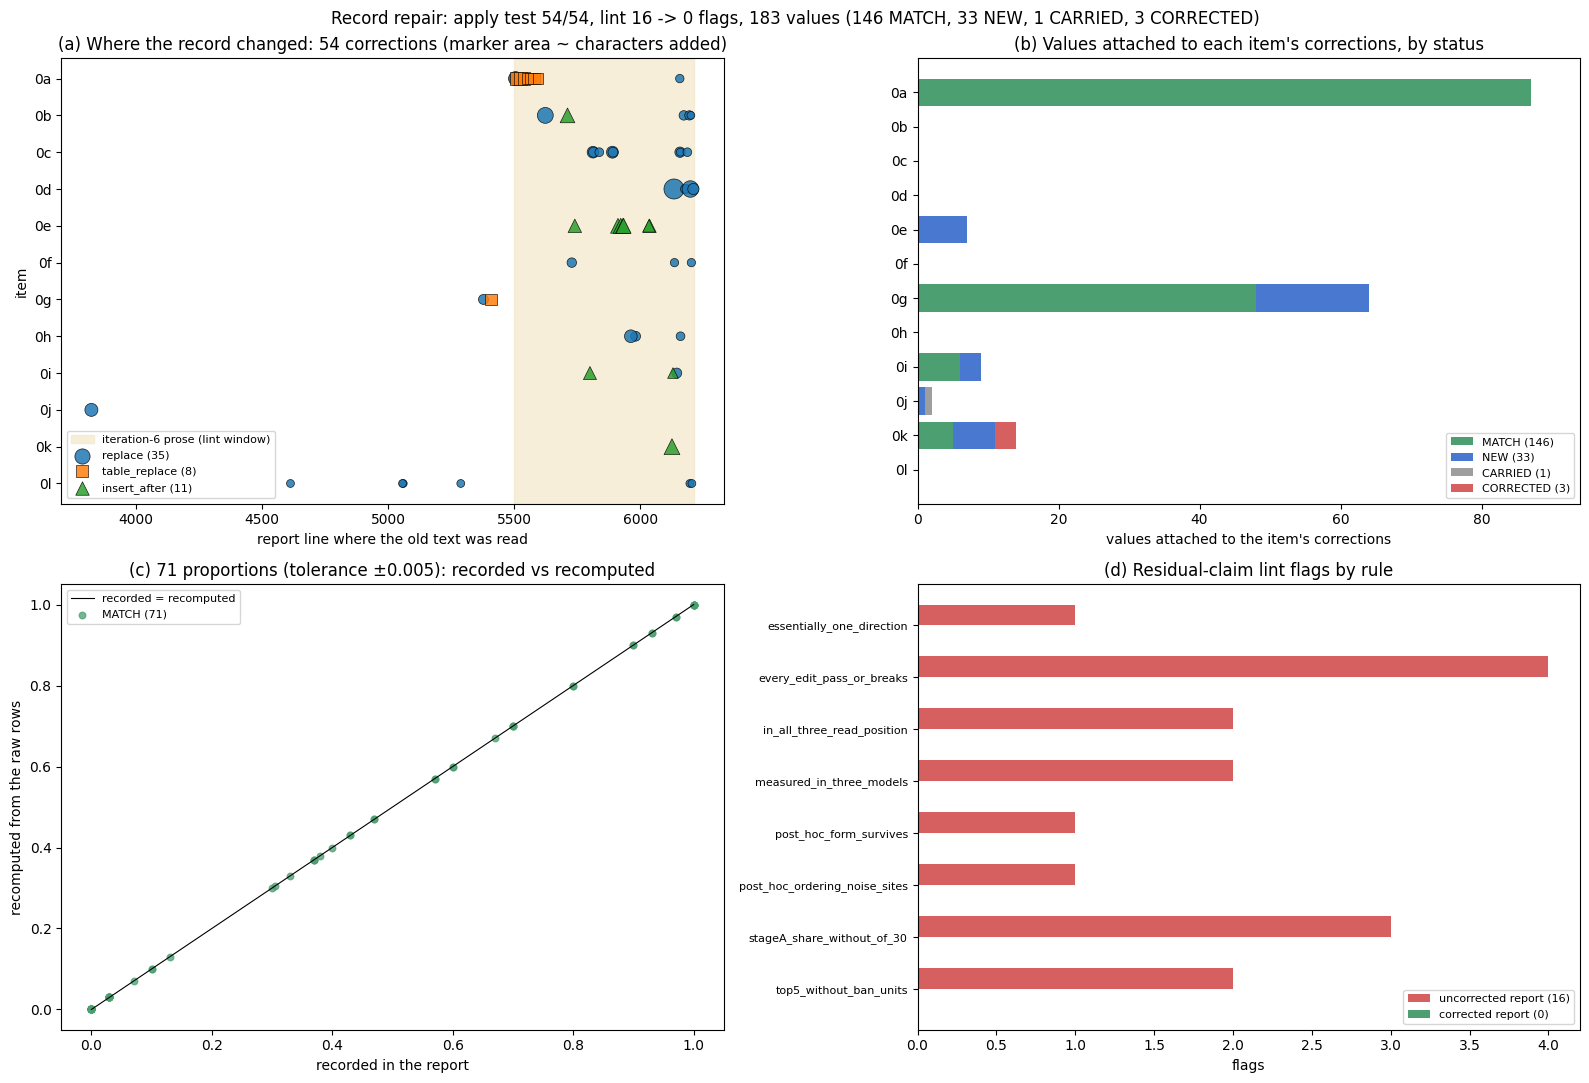

In [19]:
ITEMS = sorted({c["item"] for c in corr})
STATUS_COLORS = {"MATCH": "#4c9f70", "NEW": "#4878cf", "CARRIED": "#9e9e9e", "CORRECTED": "#d65f5f"}
KIND_MARKERS = {"replace": "o", "table_replace": "s", "insert_after": "^"}
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# (a) where in the report each correction sits
ax = axes[0, 0]
ax.axvspan(5497, 6211, color="#f3e7c9", alpha=0.7, label="iteration-6 prose (lint window)")
for kind, mk in KIND_MARKERS.items():
    cs = [c for c in corr if c["kind"] == kind]
    if cs:
        ax.scatter([c["line_at_read"] for c in cs], [ITEMS.index(c["item"]) for c in cs], marker=mk, alpha=0.85,
                   s=[25 + 0.08 * max(0, len(c["new_text"]) - len(c["old_text"])) for c in cs],
                   edgecolor="k", linewidth=0.5, label=f"{kind} ({len(cs)})")
ax.set_yticks(range(len(ITEMS)))
ax.set_yticklabels(ITEMS)
ax.invert_yaxis()
ax.set_xlabel("report line where the old text was read")
ax.set_ylabel("item")
ax.set_title(f"(a) Where the record changed: {len(corr)} corrections (marker area ~ characters added)")
ax.legend(loc="lower left", fontsize=8)

# (b) the values each item's corrections carry, by status
ax = axes[0, 1]
left = np.zeros(len(ITEMS))
for st, col in STATUS_COLORS.items():
    cnt = np.array([sum(1 for c in corr if c["item"] == it for v in c["values"] if v["status"] == st) for it in ITEMS])
    ax.barh(range(len(ITEMS)), cnt, left=left, color=col, label=f"{st} ({by_status.get(st, 0)})")
    left += cnt
ax.set_yticks(range(len(ITEMS)))
ax.set_yticklabels(ITEMS)
ax.invert_yaxis()
ax.set_xlim(0, max(left.max(), 1) * 1.08)
ax.set_xlabel("values attached to the item's corrections")
ax.set_title("(b) Values attached to each item's corrections, by status")
ax.legend(loc="lower right", fontsize=8)

# (c) shares and rates: the number the report printed against the number re-derived from raw rows
ax = axes[1, 0]
props = [v for c in corr for v in c["values"] if v["tolerance"] == "prop" and v["recorded"] is not None
         and v["recomputed"] is not None]
ax.plot([0, 1], [0, 1], color="k", linewidth=0.8, label="recorded = recomputed")
for st, col in STATUS_COLORS.items():
    ps = [v for v in props if v["status"] == st]
    if ps:
        ax.scatter([v["recorded"] for v in ps], [v["recomputed"] for v in ps], color=col, s=22, alpha=0.75,
                   label=f"{st} ({len(ps)})")
ax.set_xlabel("recorded in the report")
ax.set_ylabel("recomputed from the raw rows")
ax.set_title(f"(c) {len(props)} proportions (tolerance ±0.005): recorded vs recomputed")
ax.legend(loc="upper left", fontsize=8)

# (d) the residual-claim lint, before and after the corrections
ax = axes[1, 1]
rules = sorted({h["rule"] for h in lint_before} | {h["rule"] for h in lint_after})
y = np.arange(len(rules))
ax.barh(y - 0.2, [sum(h["rule"] == r for h in lint_before) for r in rules], height=0.4, color="#d65f5f",
        label=f"uncorrected report ({len(lint_before)})")
ax.barh(y + 0.2, [sum(h["rule"] == r for h in lint_after) for r in rules], height=0.4, color="#4c9f70",
        label=f"corrected report ({len(lint_after)})")
ax.set_yticks(y)
ax.set_yticklabels(rules, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("flags")
ax.set_title("(d) Residual-claim lint flags by rule")
ax.legend(loc="lower right", fontsize=8)

fig.suptitle(f"Record repair: apply test {apply_res['n_pass']}/{apply_res['n']}, lint {len(lint_before)} -> "
             f"{len(lint_after)} flags, {len(all_vals)} values ("
             + ", ".join(f"{by_status.get(st, 0)} {st}" for st in STATUS_COLORS) + ")", fontsize=12)
fig.tight_layout()
fig.savefig(WS / "demo_summary.png", dpi=110)
plt.show()

## Running the full pipeline

In a clone of the repository, run these commands from this artifact's folder, the one that holds `eval.py`:
```bash
bash restore.sh                     # .venv with the exact pinned versions of pyproject.toml
uv run eval.py --stages offline     # every stage from inputs/ and the caches: about 20 s, no network, no spend
python3 -I audit/rederive.py        # the independent stdlib audit: 520 checks, 7 placebos that must fail
python3 -I audit/headline_check.py  # 35 headline numbers re-derived through a separate code path
```
That run recomputes the item values from the raw rows, and it reproduces the same 54 corrections. It also rebuilds the 724-value ledger (603 MATCH, 117 NEW, 1 CARRIED, 3 CORRECTED) and `eval_out.json` with metrics M1 to M12. Running `uv run eval.py --stages all` re-calls the blind judges, which costs about USD 0.08 and needs `OPENROUTER_API_KEY`, and repeats the live web pass.